# **THEME 1 : Communication en bande de base BPSK**

In [84]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import special as sp

## **1. Canal idéal de Nyquist AWGN**

**♢ Chaîne de communication BPSK**

fonction *genBPSK*

In [85]:
def genBPSK(N):
    seq_al = np.random.uniform(0, 1, N)
    seq_al -= 0.5
    return np.sign(seq_al)

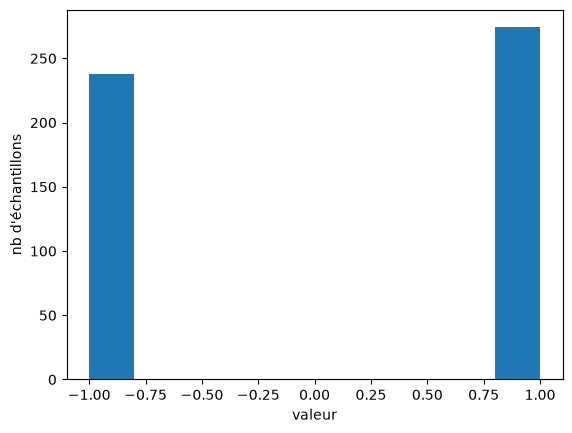

In [86]:
plt.hist(genBPSK(512))
plt.xlabel('valeur')
plt.ylabel('nb d\'échantillons')
plt.show()

fonction *genBruitN*

In [87]:
def genBruitN (V, N) :
    bruit = []
    for i in range(N) :
        b = np.random.normal(0, np.sqrt(V))
        bruit.append(b)
    return bruit

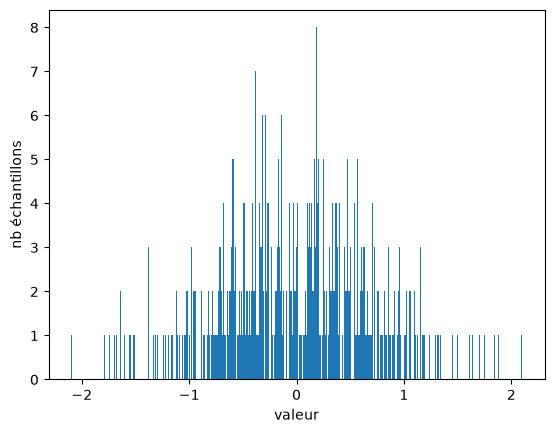

In [88]:
plt.hist(genBruitN(V, N),(N))
plt.xlabel('valeur')
plt.ylabel('nb échantillons')
plt.show()

fonction *decodeBPSK*

In [89]:
def decodeBPSK (rn) :
    return np.where(rn >= 0, 1, -1)

Simuler la chaîne de communication

C:\Users\liamn\AppData\Local\Temp\ipykernel_7724\244678962.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


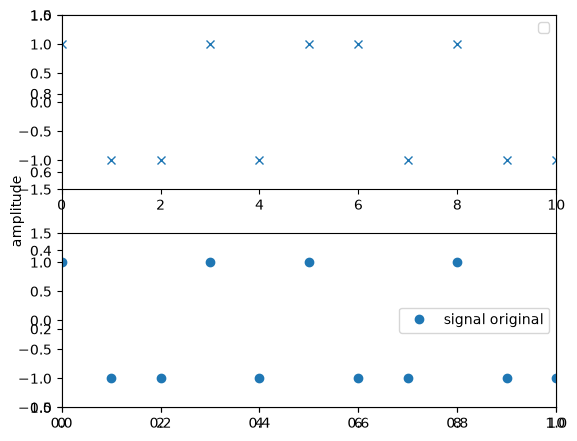

In [90]:
V = 0.5
N = 512
g0 = 1

bruit = genBruitN(V, N)
sig = genBPSK(N)
sig_sum = sig*g0 + bruit

plt.ylabel('amplitude')
plt.subplot(2, 1, 1)
plt.plot(decodeBPSK(sig_sum), 'x')
plt.ylim(-1.5, 1.5)
plt.xlim(0, 10)
plt.legend()

plt.subplot(2, 1, 2)
plt.plot(sig, 'o', label='signal original')
plt.ylim(-1.5, 1.5)
plt.xlim(0, 10)
plt.legend()

plt.tight_layout()
plt.show()

Quel est le taux d’erreur binaire à la réception (par simulation) ?

In [91]:
teb = np.sum(decodeBPSK(sig_sum) != sig)/N
print("TEB = ", teb)

TEB =  0.08203125


**♢ Taux d’erreur binaire du canal AWGN**

Relation entre rapport signal à bruit et rapport signal à bruit normalisé :

Calcul de la variance du bruit $\sigma_b^2$ pour chaque valeur $[\frac{E_b}{N_0}]_{dB}$ :

Tracer la courbe du taux d’erreur binaire

coeff = 2.0
pour 0 dB,V = 0.5 et TEB = 0.0703125
pour 1 dB,V = 0.39716411736214075 et TEB = 0.048828125
pour 2 dB,V = 0.3154786722400966 et TEB = 0.0234375
pour 3 dB,V = 0.2505936168136362 et TEB = 0.033203125
pour 4 dB,V = 0.19905358527674863 et TEB = 0.009765625
pour 5 dB,V = 0.15811388300841897 et TEB = 0.009765625
pour 6 dB,V = 0.125594321575479 et TEB = 0.00390625
pour 7 dB,V = 0.099763115748444 et TEB = 0.0
pour 8 dB,V = 0.07924465962305566 et TEB = 0.0
pour 9 dB,V = 0.06294627058970835 et TEB = 0.0
pour 10 dB,V = 0.05 et TEB = 0.0
pour 11 dB,V = 0.03971641173621407 et TEB = 0.0


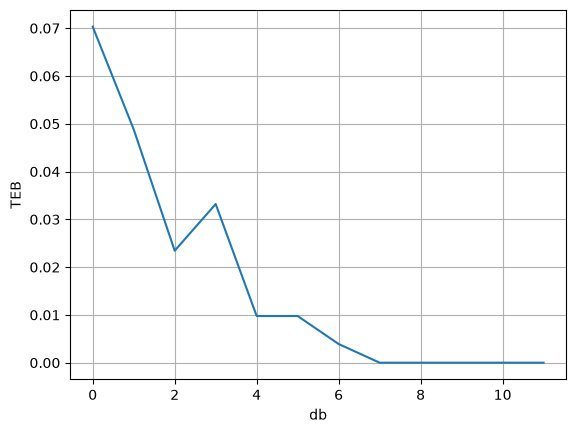

In [ ]:
#RSB = g0**2/V
#RSB_norm = 1/2 * RSB
coeff = (6*np.log2(2) / (2**2 - 1))
print ("coeff = " + str(coeff))

RSB_norm = [i for i in range(0, 12)]

def V_rsb(RSB_norm, coeff):
    V_rsb = []
    for r in RSB_norm:
        V_rsb.append(1/(coeff*10**(r/10)))
    return V_rsb

teb_list = []
for i in RSB_norm :
    V = V_rsb(RSB_norm, coeff)[i]
    bruit = genBruitN(V, N)
    sig_sum = sig*g0 + bruit
    teb = np.sum(decodeBPSK(sig_sum) != sig)/N
    teb_list.append(teb)
    print("pour " + str(RSB_norm[i]) + " dB," +  "V = " + str(V_rsb(RSB_norm, coeff)[i]) + " et TEB = " + str(teb))

plt.plot(RSB_norm, teb_list)
plt.xlabel('db')
plt.ylabel('TEB')
plt.grid(True)
plt.show()

Commenter :

La valeur de N minimale pour tracer la courbe du taux d’erreur binaire pour toute la plage de $[\frac{E_b}{N_0}]_{dB}$ :

N minimum = 380512


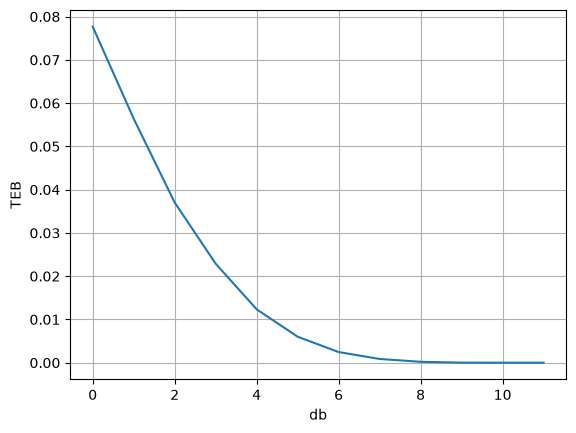

In [124]:
M = N
V = V_rsb(RSB_norm, coeff)[-1]
sig_M = genBPSK(M)
bruit_M = genBruitN(V, M)
sig_sum_M = sig_M*g0 + bruit_M
teb_M = np.sum(decodeBPSK(sig_sum_M) != sig_M)/M
teb_M_list = [0]


while 0 in teb_M_list :
    teb_M_list = []
    M += 10000
    for i in RSB_norm :
        V = V_rsb(RSB_norm, coeff)[i]
        sig_M = genBPSK(M)
        bruit_M = genBruitN(V, M)
        sig_sum_M = sig_M*g0 + bruit_M
        teb_M = np.sum(decodeBPSK(sig_sum_M) != sig_M)/M
        teb_M_list.append(teb_M)
print ("N minimum = " + str(M))


plt.plot(RSB_norm, teb_M_list)
plt.xlabel('db')
plt.ylabel('TEB')
plt.grid(True)
plt.show()

**Check point 1:** Bravo! appelez votre encadrant(e) pour valider



---



**♢ Probabilité d’erreur binaire théorique**

Tracer la courbe de la probabilité d’erreur binaire théorique. Vous pouvez utiliser la fonction *sp.erfc*

In [93]:
# code ici

**♢ Comparaison des courbes d’erreur : pratique et théorique**

Comparer la courbe pratique (obtenue via simulation) avec la courbe théorique. Commenter :

SNR (en dB) qui permet de garantir pour une probabilité d’erreur binaire d’environ $10^{-3}$ :

**Check point 2:** Bravo! appelez votre encadrant(e) pour valider



---



# **2. Interférence entre symboles (IES) et égalisation**

*fonction genSig*. Vous pouvez utiliser la fonction *lfilter*

In [94]:
from scipy.signal import lfilter
# code ici

Expression de la réponse impulsionnelle du filtre global du canal $g_n$ et $x_n$:

Visualiser le signal utile $x_n$

In [95]:
# code ici

Commenter:

**Check point 3:** Bravo! appelez votre encadrant(e) pour valider